In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.utils.class_weight import compute_class_weight

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Make results reproducible
np.random.seed(42)
tf.keras.utils.set_random_seed(42)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [2]:
url = "https://raw.githubusercontent.com/krishnaik06/ANN-CLassification-Churn/main/Churn_Modelling.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [3]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nStatistical Summary:")
display(df.describe())

print("\nTarget Variable Distribution:")
print(df["Exited"].value_counts())

print("\nTarget Distribution in Percentage:")
print((df["Exited"].value_counts(normalize=True) * 100).round(2))

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB

Missing Values:
RowNumber          0
CustomerId         0
Surname       

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000



Target Variable Distribution:
Exited
0    7963
1    2037
Name: count, dtype: int64

Target Distribution in Percentage:
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


In [4]:
# Remove columns that do not meaningfully predict customer churn
X = df.drop(
    columns=["Exited", "RowNumber", "CustomerId", "Surname"]
)

# Target variable
y = df["Exited"].astype("int32")

# Identify numerical and categorical features
numeric_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = X.select_dtypes(include=["object", "category"]).columns.tolist()

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nNumerical Features:")
print(numeric_cols)

print("\nCategorical Features:")
print(categorical_cols)

print("\nTarget values: 0 = Stayed, 1 = Exited")

Feature shape: (10000, 10)
Target shape: (10000,)

Numerical Features:
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']

Categorical Features:
['Geography', 'Gender']

Target values: 0 = Stayed, 1 = Exited


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (8000, 10)
Testing Features: (2000, 10)
Training Target: (8000,)
Testing Target: (2000,)


In [6]:
# Support both recent and older scikit-learn versions
try:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    )
except TypeError:
    encoder = OneHotEncoder(
        handle_unknown="ignore",
        sparse=False
    )

# Preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("cat", encoder, categorical_cols)
    ]
)

# Fit on training data only to avoid data leakage
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nFeature preprocessing completed successfully!")

Processed training shape: (8000, 13)
Processed testing shape: (2000, 13)

Feature preprocessing completed successfully!


In [7]:
baseline_model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),
    Dense(32, activation="relu"),
    Dense(16, activation="relu"),
    Dense(1, activation="sigmoid")
])

baseline_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

baseline_history = baseline_model.fit(
    X_train_processed,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

print("\nBaseline model training completed!")

Epoch 1/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.7848 - loss: 0.4735 - val_accuracy: 0.8100 - val_loss: 0.4258
Epoch 2/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8231 - loss: 0.4124 - val_accuracy: 0.8400 - val_loss: 0.3966
Epoch 3/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.8416 - loss: 0.3857 - val_accuracy: 0.8556 - val_loss: 0.3690
Epoch 4/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.8478 - loss: 0.3662 - val_accuracy: 0.8669 - val_loss: 0.3492
Epoch 5/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8516 - loss: 0.3550 - val_accuracy: 0.8681 - val_loss: 0.3399
Epoch 6/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8527 - loss: 0.3494 - val_accuracy: 0.8681 - val_loss: 0.3355
Epoch 7/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8539 - loss: 0.3459 - val_accuracy: 0.8706 - val_loss: 0.3329
Epoch 8/30
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8561 - loss: 0.3434 - val_accuracy: 0.

In [8]:
baseline_probabilities = baseline_model.predict(
    X_test_processed,
    verbose=0
).ravel()

baseline_predictions = (
    baseline_probabilities >= 0.5
).astype(int)

baseline_accuracy = accuracy_score(
    y_test,
    baseline_predictions
)

print("Baseline Model Accuracy:", round(baseline_accuracy * 100, 2), "%")

print("\nBaseline Confusion Matrix:")
print(confusion_matrix(y_test, baseline_predictions, labels=[0, 1]))

print("\nBaseline Classification Report:")
print(
    classification_report(
        y_test,
        baseline_predictions,
        target_names=["Stayed", "Exited"],
        zero_division=0
    )
)

Baseline Model Accuracy: 85.95 %

Baseline Confusion Matrix:
[[1525   68]
 [ 213  194]]

Baseline Classification Report:
              precision    recall  f1-score   support

      Stayed       0.88      0.96      0.92      1593
      Exited       0.74      0.48      0.58       407

    accuracy                           0.86      2000
   macro avg       0.81      0.72      0.75      2000
weighted avg       0.85      0.86      0.85      2000



In [9]:
classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.to_numpy()
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Class Weights:", class_weights)

Class Weights: {0: 0.6279434850863422, 1: 2.4539877300613497}


In [10]:
model = Sequential([
    Input(shape=(X_train_processed.shape[1],)),

    Dense(64, activation="relu"),
    Dropout(0.30),

    Dense(32, activation="relu"),
    Dropout(0.20),

    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Stop training if validation loss stops improving
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

# Reduce learning rate when validation loss plateaus
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=4,
    min_lr=0.00001,
    verbose=1
)

history = model.fit(
    X_train_processed,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

print("\nImproved neural network training completed!")

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.6316 - loss: 0.6202 - val_accuracy: 0.7150 - val_loss: 0.5589 - learning_rate: 0.0010
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7075 - loss: 0.5715 - val_accuracy: 0.7487 - val_loss: 0.5155 - learning_rate: 0.0010
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7289 - loss: 0.5413 - val_accuracy: 0.7644 - val_loss: 0.4960 - learning_rate: 0.0010
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7439 - loss: 0.5270 - val_accuracy: 0.7719 - val_loss: 0.4813 - learning_rate: 0.0010
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7569 - loss: 0.5102 - val_accuracy: 0.7781 - val_loss: 0.4665 - learning_rate: 0.0010
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7630 - loss: 0.5045 - val_accuracy: 0.7856 - val_loss: 0.4688 - learning_rate: 0.0010
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7691 - loss: 0.

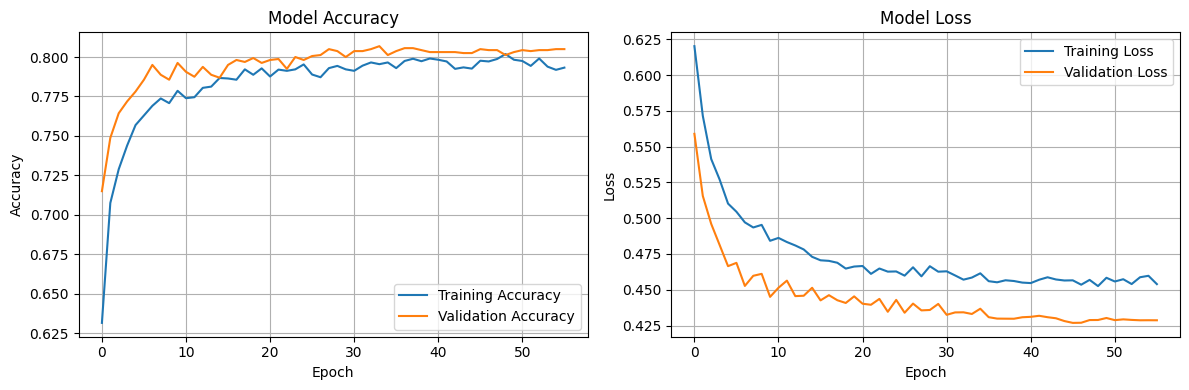

In [11]:
plt.figure(figsize=(12, 4))

# Accuracy graph
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

# Loss graph
plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

IMPROVED NEURAL NETWORK RESULTS

Accuracy Score: 0.7970
Accuracy Percentage: 79.70%

Confusion Matrix:
[[1284  309]
 [  97  310]]


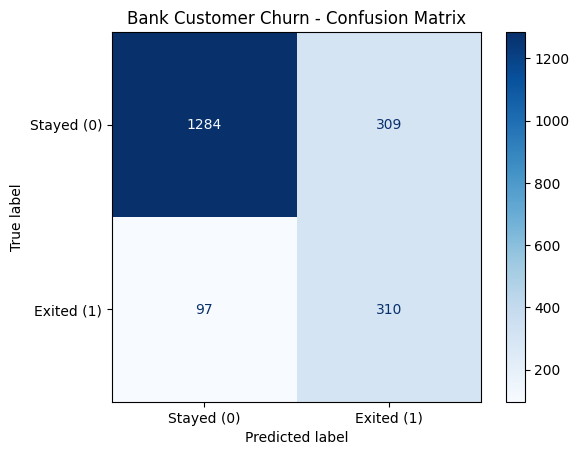


Classification Report:
              precision    recall  f1-score   support

      Stayed     0.9298    0.8060    0.8635      1593
      Exited     0.5008    0.7617    0.6043       407

    accuracy                         0.7970      2000
   macro avg     0.7153    0.7838    0.7339      2000
weighted avg     0.8425    0.7970    0.8107      2000



In [12]:
# Predict churn probabilities for the test set
y_prob = model.predict(
    X_test_processed,
    verbose=0
).ravel()

# Convert probabilities into binary predictions
y_pred = (y_prob >= 0.5).astype(int)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)

print("=" * 50)
print("IMPROVED NEURAL NETWORK RESULTS")
print("=" * 50)

print(f"\nAccuracy Score: {accuracy:.4f}")
print(f"Accuracy Percentage: {accuracy * 100:.2f}%")

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

print("\nConfusion Matrix:")
print(cm)

# Plot confusion matrix
display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed (0)", "Exited (1)"]
)

display_matrix.plot(
    cmap="Blues",
    values_format="d"
)

plt.title("Bank Customer Churn - Confusion Matrix")
plt.show()

# Additional evaluation metrics
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Stayed", "Exited"],
        digits=4,
        zero_division=0
    )
)

In [13]:
from sklearn.metrics import precision_score, recall_score, f1_score

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Churn Precision",
        "Churn Recall",
        "Churn F1-Score"
    ],
    "Baseline Model": [
        accuracy_score(y_test, baseline_predictions),
        precision_score(y_test, baseline_predictions, zero_division=0),
        recall_score(y_test, baseline_predictions, zero_division=0),
        f1_score(y_test, baseline_predictions, zero_division=0)
    ],
    "Improved Model": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0)
    ]
})

display(results.round(4))

,Metric,Baseline Model,Improved Model
0,Accuracy,0.8595,0.7970
1,Churn Precision,0.7405,0.5008
2,Churn Recall,0.4767,0.7617
3,Churn F1-Score,0.5800,0.6043


In [14]:
"Conclusion: A neural network-based classifier was developed to predict bank customer churn using the Churn Modelling dataset. The dataset was divided into training and testing sets. Unnecessary identifier columns were removed, categorical variables were encoded, and numerical variables were standardized. A baseline neural network was trained and evaluated, followed by an improved model incorporating dropout regularization, class weighting, early stopping, and learning-rate reduction. The final model's performance was evaluated using the accuracy score, confusion matrix, and classification report. These metrics help assess both overall prediction accuracy and the model's ability to identify customers who leave the bank."

"Conclusion: A neural network-based classifier was developed to predict bank customer churn using the Churn Modelling dataset. The dataset was divided into training and testing sets. Unnecessary identifier columns were removed, categorical variables were encoded, and numerical variables were standardized. A baseline neural network was trained and evaluated, followed by an improved model incorporating dropout regularization, class weighting, early stopping, and learning-rate reduction. The final model's performance was evaluated using the accuracy score, confusion matrix, and classification report. These metrics help assess both overall prediction accuracy and the model's ability to identify customers who leave the bank."